In [1]:
import eu9_osm
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
import textwrap

In [2]:
# Bbox: west, south, east, north
bbox = (-8.434539, 40.203395, -8.416536, 40.212523)
crs = "EPSG:3763"

In [3]:
# OSM data
buildings = eu9_osm.features_from_bbox(bbox=bbox, tags={"building": True}, clip=True)
streets = eu9_osm.features_from_bbox(bbox=bbox, tags={"highway": True}, clip=True)
water = eu9_osm.features_from_bbox(bbox=bbox, tags={"natural": "water", "waterway": "riverbank"}, clip=True)
parks = eu9_osm.features_from_bbox(bbox=bbox, tags={"leisure": ["park", "garden"]}, clip=True)

In [4]:
# Keep only polygons
buildings = buildings[buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
water = water[water.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks = parks[parks.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
# Keep only lines
streets = streets[streets.geometry.geom_type.isin(["LineString", "MultiLineString"])].copy()

In [5]:
# Reproject
buildings = buildings.to_crs(crs)
streets = streets.to_crs(crs)
water = water.to_crs(crs)
parks = parks.to_crs(crs)

# Map extent to projected coords
extent = gpd.GeoSeries([box(*bbox)], crs="EPSG:4326").to_crs(crs)
xmin, ymin, xmax, ymax = extent.total_bounds

In [6]:
highlight_list=["college", "library", "place_of_worship", "theater", "townhall"]
highlighted_buildings = buildings[buildings["amenity"].isin(highlight_list)]

In [7]:
# Road lw
road_widths = {
    "motorway": 12,
    "trunk": 11,
    "primary": 10,
    "secondary": 9,
    "tertiary": 8,
    "residential": 6,
    "living_street": 5,
    "pedestrian": 5,
    "service": 3,
    "footway": 2,
    "path": 1.5,
    "steps": 2
}

In [8]:
# Buffer roads
streets["width"] = streets["highway"].map(road_widths).fillna(4)
street_polygons = streets.copy()
street_polygons["geometry"] = [geom.buffer(width / 2, cap_style=2, join_style=2) 
                               for geom, width in zip(streets.geometry, streets["width"])]

# Separate street polygons into one poly
road_union = street_polygons.geometry.union_all()
road_surface = gpd.GeoSeries([road_union], crs=crs)

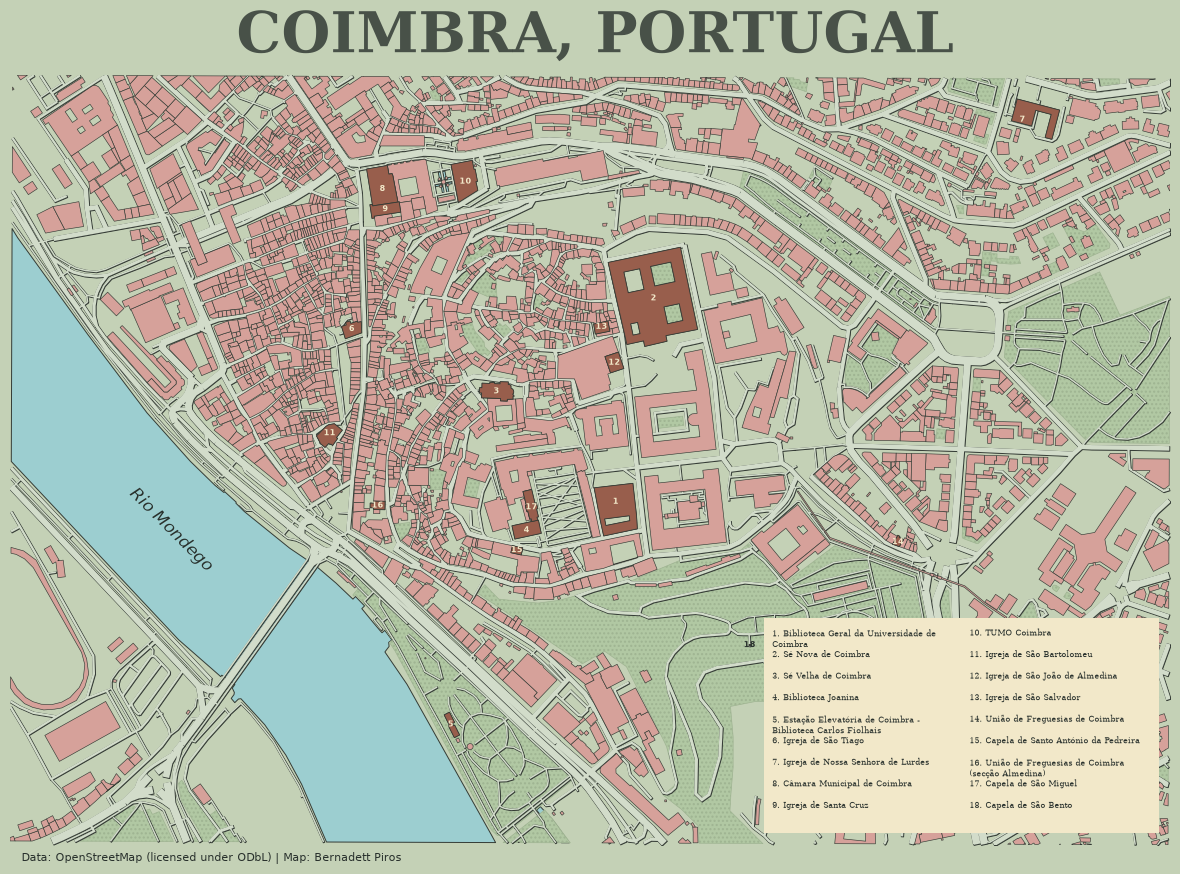

In [9]:
fig, ax = plt.subplots(figsize=(12, 10), facecolor= "#C4D1B6")

# Water
water.plot(ax=ax, facecolor="#9CCED0", ec="#343B35", lw=0.7, zorder=1)

# Parks and gardens
parks.plot(ax=ax, facecolor="#B1C8A3", hatch="....", ec="#9fb492", lw=0.5, zorder=2)

# Streets - dark outlines down
road_surface.plot(ax=ax, facecolor="#343B35", ec="#343B35", lw=0.7, zorder=3)

# Streets - pale surfaces on top
road_surface.plot(ax=ax, facecolor="#D2DCCA", ec="none", zorder=4)

# Buildings
buildings.plot(ax=ax, facecolor="#D6A19A", ec="#343B35", lw=0.45, zorder=5)

# Highlighted buildings
highlighted_buildings.plot(ax=ax, facecolor="#985E4C", ec="#343B35", lw=0.6, zorder=6)

# Numbering buildings
for i, (idx, row) in enumerate(highlighted_buildings.iterrows()):    
    point = row.geometry.representative_point()
    ax.text(point.x, point.y, str(i + 1), color="#29312D" if i==17 else "#F2E8C9", size=6, weight="bold", ha="center", va="center", zorder=10)  
        

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_facecolor("#C4D1B6")
ax.set_aspect("equal")
ax.axis("off")

# Add river name
river = water.iloc[[0]].copy()
point = river.geometry.iloc[0].representative_point()

ax.text(point.x, point.y, "Rio Mondego", color="#29312D", size=12, fontstyle="italic",
        rotation=-45, ha="center", va="center", zorder=10)

# Inset ax
inset_ax = ax.inset_axes([0.65, 0.015, 0.34, 0.28])

n = len(highlighted_buildings)
rows_per_column = (n + 1) // 2

for i, (idx, row) in enumerate(highlighted_buildings.iterrows()):   
    
    col = i // rows_per_column    
    row_number = i % rows_per_column

    x = 0.02 + col * 0.50
    y = 0.95 - row_number * (0.90 / rows_per_column)

    name = row["name"]

    # Wrap long names
    name = textwrap.fill(str(row["name"]), width=35)

    inset_ax.text(x, y,
                  f"{i + 1}. {name}",
                  transform=inset_ax.transAxes, color="#29312D", size=6, fontfamily="DejaVu Serif", ha="left", va="top")

inset_ax.set_facecolor("#F2E8C9")
inset_ax.set_xticks([])
inset_ax.set_yticks([])

for spine in inset_ax.spines.values():
    spine.set_visible(False)

#Title
fig.text(0.5, 0.95, "COIMBRA, PORTUGAL", color="#29312D", alpha=0.8, size=40, weight="bold", fontfamily="serif", ha="center", va="top")

# Caption
ax.text(0.01, -0.025,
        "Data: OpenStreetMap (licensed under ODbL) | Map: Bernadett Piros",
        transform=ax.transAxes, color="#29312D", size=8, ha="left",va="bottom", zorder=10)

plt.tight_layout()

plt.show()

# Save image
#plt.savefig("coimbra_historical_style.png", bbox_inches="tight", pad_inches=0.2)